# viewshed of UC berkeley

In [21]:
from pathlib import Path
from getpass import getpass
import subprocess
import shutil
import warnings

import numpy as np
import pandas as pd
import geopandas as gpd
import osmnx as ox
import rasterio
import requests
import matplotlib.pyplot as plt

from rasterio.features import rasterize
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.transform import from_origin
from shapely.geometry import box

print("OSMnx version:", ox.__version__)
print("GDAL available:", shutil.which("gdal_viewshed"))

OSMnx version: 2.1.1
GDAL available: /opt/anaconda3/envs/geospatial/bin/gdal_viewshed


In [25]:
# Approximate UC Berkeley campus bounding box
west, south, east, north = -122.275, 37.865, -122.245, 37.880

# Download all mapped building features
buildings = ox.features_from_bbox(
    (west, south, east, north),
    tags={"building": True}
)

# Keep building polygons only
buildings = buildings[
    buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

buildings = buildings[
    buildings.geometry.notna() & ~buildings.geometry.is_empty
].copy()

print(f"Buildings downloaded: {len(buildings)}")

Buildings downloaded: 3243


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)


In [30]:
# Use the bounding box from your successful building download
west, south, east, north = -122.275, 37.865, -122.245, 37.880

# Query university-tagged features directly from OpenStreetMap
campus_candidates = ox.features_from_bbox(
    (west, south, east, north),
    tags={"amenity": "university"}
)

# Inspect names and geometry types
campus_candidates["geometry_type"] = (
    campus_candidates.geometry.geom_type
)

cols = [
    c for c in [
        "name", "amenity", "operator", "geometry_type"
    ]
    if c in campus_candidates.columns
]

display(campus_candidates[cols])

/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)


name  \
element  id                                                               
node     12007380847                  Berkeley Wireless Research Center   
relation 2814221                     University of California, Berkeley   
way      24025432                       Goldman School of Public Policy   
         109193723    University of California, Berkeley - Clark Ker...   
         227644219                           Pacific School of Religion   
         227755109                Church Divinity School of the Pacific   
         429259479                American Baptist Seminary of the West   
         1387749433                                The Wright Institute   

                         amenity                             operator  \
element  id                                                             
node     12007380847  university  University of California - Berkeley   
relation 2814221      university   University of California, Berkeley   
way      24025432     university   University of California, Berkeley   
         109193723    university                                  NaN   
         227644219    university                                  NaN   
         227755109    university                                  NaN   
         429259479    university                                  NaN   
         1387749433   university                                  NaN   

                     geometry_type  
element  id                         
node     12007380847         Point  
relation 2814221      MultiPolygon  
way      24025432          Polygon  
         109193723         Polygon  
         227644219         Polygon  
         227755109         Polygon  
         429259479         Polygon  
         1387749433        Polygon

In [31]:
campus_polygons = campus_candidates[
    campus_candidates.geometry.geom_type.isin(
        ["Polygon", "MultiPolygon"]
    )
].copy()

display(campus_polygons[cols])

name  \
element  id                                                              
relation 2814221                    University of California, Berkeley   
way      24025432                      Goldman School of Public Policy   
         109193723   University of California, Berkeley - Clark Ker...   
         227644219                          Pacific School of Religion   
         227755109               Church Divinity School of the Pacific   
         429259479               American Baptist Seminary of the West   
         1387749433                               The Wright Institute   

                        amenity                            operator  \
element  id                                                           
relation 2814221     university  University of California, Berkeley   
way      24025432    university  University of California, Berkeley   
         109193723   university                                 NaN   
         227644219   university                                 NaN   
         227755109   university                                 NaN   
         429259479   university                                 NaN   
         1387749433  university                                 NaN   

                    geometry_type  
element  id                        
relation 2814221     MultiPolygon  
way      24025432         Polygon  
         109193723        Polygon  
         227644219        Polygon  
         227755109        Polygon  
         429259479        Polygon  
         1387749433       Polygon

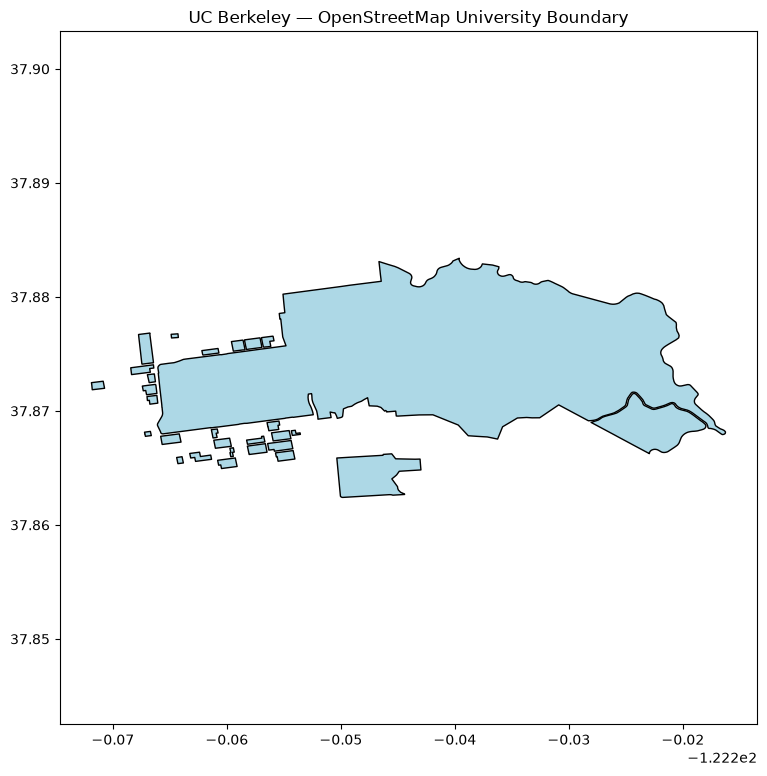

In [32]:
# Select the exact campus relation by its OSM ID
campus_boundary = campus_candidates.loc[
    ("relation", 2814221), "geometry"
]

campus = gpd.GeoDataFrame(
    {"name": ["University of California, Berkeley"]},
    geometry=[campus_boundary],
    crs=campus_candidates.crs
)

# Inspect the campus boundary
campus.plot(
    figsize=(9, 9),
    edgecolor="black",
    facecolor="lightblue"
)
plt.title("UC Berkeley — OpenStreetMap University Boundary")
plt.axis("equal")
plt.show()

In [33]:
# Download buildings within the campus polygon
buildings = ox.features_from_polygon(
    campus_boundary,
    tags={"building": True}
)

# Keep building footprints
buildings = buildings[
    buildings.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
].copy()

buildings = buildings[
    buildings.geometry.notna() & ~buildings.geometry.is_empty
].copy()

# Keep only footprints that intersect the campus boundary
buildings = gpd.clip(buildings, campus)

print("Buildings in campus boundary:", len(buildings))

Buildings in campus boundary: 458


/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/set_operations.py:451: RuntimeWarning: invalid value encountered in union
  return lib.union(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: RuntimeWarning: invalid value encountered in intersects
  return lib.intersects(a, b, **kwargs)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/shapely/predicates.py:878: Runt

In [34]:
import pandas as pd
import numpy as np

def parse_height(value):
    if pd.isna(value):
        return np.nan

    s = str(value).strip().lower()

    try:
        if "ft" in s or "'" in s:
            s = (
                s.replace("feet", "")
                 .replace("foot", "")
                 .replace("ft", "")
                 .replace("'", "")
                 .strip()
            )
            return float(s) * 0.3048

        s = (
            s.replace("meters", "")
             .replace("meter", "")
             .replace("metres", "")
             .replace("metre", "")
             .replace(" m", "")
             .replace("m", "")
             .strip()
        )
        return float(s)

    except (ValueError, TypeError):
        return np.nan


buildings["height_m"] = buildings["height"].apply(parse_height)

buildings["levels_num"] = pd.to_numeric(
    buildings["building:levels"],
    errors="coerce"
)

buildings["estimated_height_m"] = buildings["height_m"]

use_levels = (
    buildings["estimated_height_m"].isna()
    & buildings["levels_num"].notna()
)

# Approximate 3.2 meters per floor
buildings.loc[use_levels, "estimated_height_m"] = (
    buildings.loc[use_levels, "levels_num"] * 3.2
)

buildings["height_source"] = np.select(
    [
        buildings["height_m"].notna(),
        buildings["levels_num"].notna()
    ],
    [
        "Mapped height",
        "Estimated from floor count"
    ],
    default="Unknown"
)

print(buildings["height_source"].value_counts())

height_source
Unknown                       286
Estimated from floor count    166
Mapped height                   6
Name: count, dtype: int64


In [35]:
height_columns = [
    c for c in [
        "name",
        "building",
        "height",
        "building:levels",
        "height_m",
        "estimated_height_m",
        "height_source"
    ]
    if c in buildings.columns
]

display(buildings[height_columns].head(30))

print("\nSummary")
print("Total buildings:", len(buildings))
print("Explicit mapped heights:", buildings["height_m"].notna().sum())
print("Floor counts:", buildings["levels_num"].notna().sum())
print("Unknown heights:", buildings["estimated_height_m"].isna().sum())

# # Save spatial and tabular outputs
# buildings.to_file(
#     "berkeley_campus_buildings.gpkg",
#     layer="buildings",
#     driver="GPKG"
# )

# buildings.drop(columns="geometry").to_csv(
#     "berkeley_campus_building_heights.csv",
#     index=True
# )

name      building   height  \
element  id                                                                   
way      671192885                               NaN        school      NaN   
         183687973          Fenwick Weavers' Village    apartments      NaN   
         183688471       Rochdale Village Building D    apartments      NaN   
         183689093       Rochdale Village Building C    apartments      NaN   
         183688472       Rochdale Village Building E    apartments      NaN   
         183690577       Rochdale Village Building B    apartments      NaN   
         183688276               Rochdale Apartments    apartments      NaN   
         109193722               Beverly Cleary Hall     dormitory      NaN   
         1080852427                              NaN        retail      NaN   
relation 6141724             Maximo Martinez Commons    apartments      NaN   
         9352938                                 NaN        school      NaN   
way      109194851                               NaN        school      NaN   
         109194852       Ellsworth Parking Structure           yes      NaN   
         1011322275                              NaN           yes      NaN   
         1531752525  Bancroft Fulton Student Housing  construction  84.1248   
         545790162                               NaN           yes      NaN   
         24025444                        Tang Center           yes      NaN   
         545790161                               NaN    commercial      NaN   
         109192949                Founder's Building           yes      NaN   
         43150624                    Banway Building    university      NaN   
         41746383                    Ida Sproul Hall     dormitory      NaN   
         41746395                     Priestley Hall     dormitory      NaN   
         41746370                                NaN           yes      NaN   
         431330565                               NaN           yes      NaN   
         431330587                               NaN           yes      NaN   
         41746358                        Norton Hall     dormitory      NaN   
         41746363                   Spens-Black Hall     dormitory      NaN   
         417682513                     Eshleman Hall    university      NaN   
         1037276017                              NaN          roof      NaN   
         24025430                    Zellerbach Hall       theatre      NaN   

                    building:levels  height_m  estimated_height_m  \
element  id                                                         
way      671192885                1       NaN              3.2000   
         183687973              NaN       NaN                 NaN   
         183688471              NaN       NaN                 NaN   
         183689093              NaN       NaN                 NaN   
         183688472              NaN       NaN                 NaN   
         183690577              NaN       NaN                 NaN   
         183688276              NaN       NaN                 NaN   
         109193722              NaN       NaN                 NaN   
         1080852427               1       NaN              3.2000   
relation 6141724                  6       NaN             19.2000   
         9352938                NaN       NaN                 NaN   
way      109194851              NaN       NaN                 NaN   
         109194852              NaN       NaN                 NaN   
         1011322275             NaN       NaN                 NaN   
         1531752525              23   84.1248             84.1248   
         545790162              NaN       NaN                 NaN   
         24025444               NaN       NaN                 NaN   
         545790161              NaN       NaN                 NaN   
         109192949              NaN       NaN                 NaN   
         43150624               NaN       NaN                 NaN   
 


Summary
Total buildings: 458
Explicit mapped heights: 6
Floor counts: 167
Unknown heights: 286


In [36]:
import numpy as np

buildings["viewshed_height_m"] = buildings["estimated_height_m"]

# Report coverage
known = buildings["viewshed_height_m"].notna()

print(f"Total buildings: {len(buildings)}")
print(f"Buildings with usable heights: {known.sum()}")
print(f"Buildings with unknown heights: {(~known).sum()}")
print(f"Height coverage: {known.mean() * 100:.1f}%")

Total buildings: 458
Buildings with usable heights: 172
Buildings with unknown heights: 286
Height coverage: 37.6%


['element', 'id', 'addr:state', 'building', 'ele', 'gnis:feature_id', 'name', 'source', 'note', 'addr:housenumber', 'addr:street', 'building:levels', 'access:disabled', 'air_conditioning', 'amenity', 'internet_access', 'internet_access:fee', 'name:etymology:wikidata', 'name:etymology:wikipedia', 'operator', 'operator:type', 'operator:wikidata', 'website', 'wheelchair', 'wikidata', 'old_name', 'access', 'architect', 'bell_tower', 'bells', 'contact:yelp', 'description', 'display', 'faces', 'height', 'man_made', 'multiple', 'official_name', 'opening_hours', 'sound', 'start_date', 'start_date:bells', 'support', 'tourism', 'tower:construction', 'tower:type', 'url', 'viewpoint', 'visibility', 'wikipedia', 'alt_name', 'last_renovation', 'layer', 'level', 'addr:housename', 'disused', 'addr:postcode', 'disused:museum', 'disused:tourism', 'fixme', 'historic', 'occupant', 'comment', 'addr:city', 'capacity', 'charge', 'fee', 'parking', 'surface', 'addr:country', 'phone', 'loc_name', 'owner', 'heri

In [89]:

import numpy as np
import pandas as pd

# Preserve existing mapped and floor-based height estimates
buildings["viewshed_height_m"] = pd.to_numeric(
    buildings["estimated_height_m"],
    errors="coerce"
)

# Track which buildings need an imputed height
buildings["height_imputed"] = (
    buildings["viewshed_height_m"].isna()
)

# Convert the proposed 45–70 ft range to meters
min_height_m = 70 * 0.3048
max_height_m = 80 * 0.3048
default_height_m = (min_height_m + max_height_m) / 2

# Fill only missing heights with the midpoint
buildings.loc[
    buildings["height_imputed"],
    "viewshed_height_m"
] = default_height_m

# Report the result
print("Height imputation summary")
print("-------------------------")
print(f"Buildings: {len(buildings):,}")
print(
    "Buildings with existing estimates:",
    int((~buildings["height_imputed"]).sum())
)
print(
    "Buildings assigned default height:",
    int(buildings["height_imputed"].sum())
)
print(f"Imputed height: {default_height_m:.2f} m")
print(f"Equivalent: {default_height_m / 0.3048:.1f} ft")

print("\nFinal height summary (meters):")
print(buildings["viewshed_height_m"].describe())


Height imputation summary
-------------------------
Buildings: 458
Buildings with existing estimates: 172
Buildings assigned default height: 286
Imputed height: 22.86 m
Equivalent: 75.0 ft

Final height summary (meters):
count    458.000000
mean      19.693198
std        8.353729
min        3.200000
25%       14.500000
50%       22.860000
75%       22.860000
max       93.600000
Name: viewshed_height_m, dtype: float64


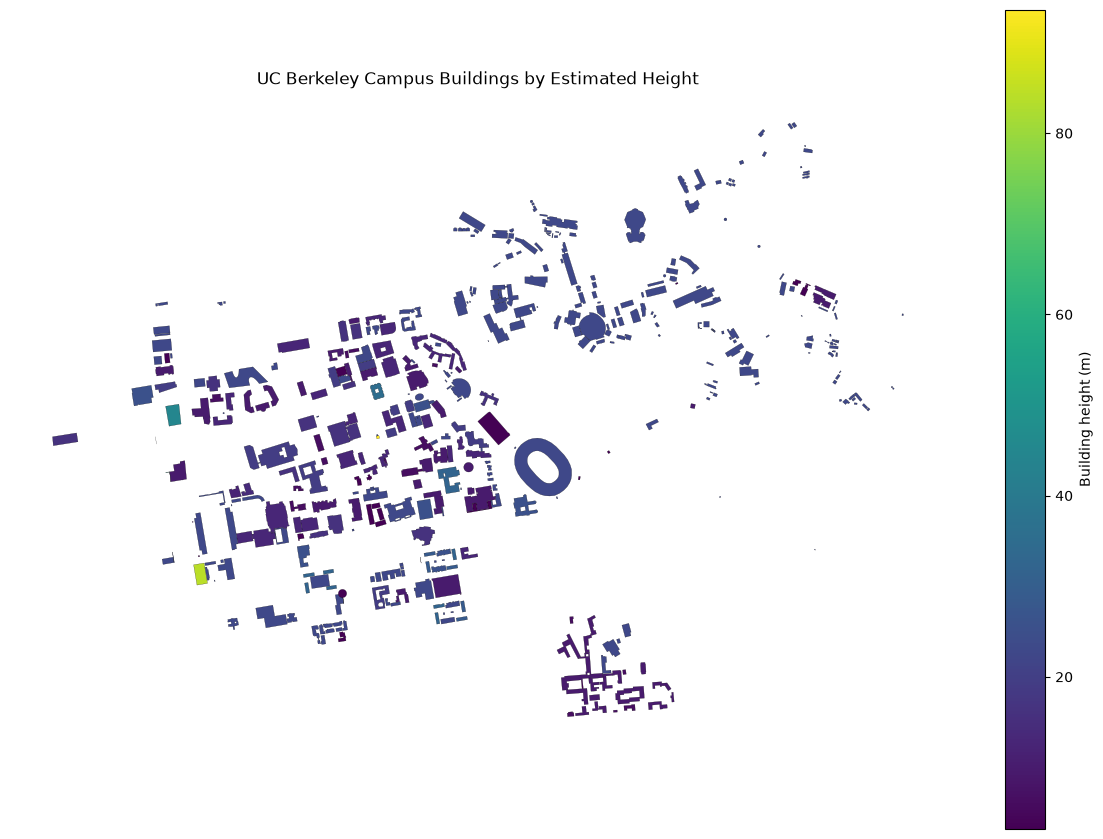

In [90]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors

fig, ax = plt.subplots(figsize=(12, 12))

buildings.plot(
    column="viewshed_height_m",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Building height (m)", "shrink": 0.7},
    edgecolor="black",
    linewidth=0.15,
    ax=ax,
    missing_kwds={"color": "lightgrey"}
)

ax.set_title("UC Berkeley Campus Buildings by Estimated Height")
ax.set_axis_off()
plt.tight_layout()
plt.show()

In [91]:
buildings.to_file(
    "berkeley_campus_buildings_with_heights.gpkg",
    layer="buildings",
    driver="GPKG"
)

## have data now viewshed analysis

In [92]:

import os
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

dem_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/output_USGS10m.tif"
buildings_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_campus_buildings_with_heights.gpkg"

print("DEM exists:", os.path.exists(dem_path))
print("Buildings exist:", os.path.exists(buildings_path))

with rasterio.open(dem_path) as src:
    print("\nDEM CRS:", src.crs)
    print("DEM resolution:", src.res)
    print("DEM bounds:", src.bounds)
    print("DEM dimensions:", src.width, "x", src.height)

buildings = gpd.read_file(buildings_path, layer="buildings")

print("\nBuilding CRS:", buildings.crs)
print("Number of buildings:", len(buildings))
print("Available columns:", buildings.columns.tolist())
print(buildings[["viewshed_height_m"]].describe())


DEM exists: True
Buildings exist: True

DEM CRS: EPSG:4269
DEM resolution: (9.259260000000115e-05, 9.259259999999984e-05)
DEM bounds: BoundingBox(left=-122.27758797529287, bottom=37.8610157880949, right=-122.21258797009287, top=37.8854602344949)
DEM dimensions: 702 x 264

Building CRS: EPSG:4326
Number of buildings: 458
Available columns: ['element', 'id', 'addr:state', 'building', 'ele', 'gnis:feature_id', 'name', 'source', 'note', 'addr:housenumber', 'addr:street', 'building:levels', 'access:disabled', 'air_conditioning', 'amenity', 'internet_access', 'internet_access:fee', 'name:etymology:wikidata', 'name:etymology:wikipedia', 'operator', 'operator:type', 'operator:wikidata', 'website', 'wheelchair', 'wikidata', 'old_name', 'access', 'architect', 'bell_tower', 'bells', 'contact:yelp', 'description', 'display', 'faces', 'height', 'man_made', 'multiple', 'official_name', 'opening_hours', 'sound', 'start_date', 'start_date:bells', 'support', 'tourism', 'tower:construction', 'tower:type

In [93]:

import numpy as np
import geopandas as gpd
import rasterio
from rasterio.features import rasterize

output_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

height_raster_path = f"{output_dir}/berkeley_building_heights.tif"
surface_path = f"{output_dir}/berkeley_surface_elevation.tif"

# Read the DEM and preserve its exact grid
with rasterio.open(dem_path) as src:
    dem = src.read(1, masked=True)
    profile = src.profile.copy()
    transform = src.transform
    dem_crs = src.crs
    dem_shape = (src.height, src.width)

# Reproject building footprints into the DEM coordinate system
buildings = buildings.to_crs(dem_crs)

# Keep valid geometries with usable heights
b = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings["viewshed_height_m"].notna()
].copy()

b["viewshed_height_m"] = b["viewshed_height_m"].astype(float)

# Rasterize buildings; each occupied cell gets its building height
height_array = rasterize(
    shapes=(
        (geom, float(height))
        for geom, height in zip(
            b.geometry,
            b["viewshed_height_m"]
        )
    ),
    out_shape=dem_shape,
    transform=transform,
    fill=0,
    dtype="float32",
    all_touched=True
)

# Outside the DEM's valid data footprint remains NoData
height_array = np.where(
    np.ma.getmaskarray(dem),
    -9999,
    height_array
).astype("float32")

# Save building-height raster using the DEM's grid
height_profile = profile.copy()
height_profile.update(
    dtype="float32",
    count=1,
    nodata=-9999,
    compress="lzw"
)

with rasterio.open(height_raster_path, "w", **height_profile) as dst:
    dst.write(height_array, 1)

# Add building heights to bare-earth elevation
dem_values = dem.filled(np.nan).astype("float32")
surface = dem_values.copy()

valid = np.isfinite(dem_values)
inside_building = (height_array > 0) & valid

surface[inside_building] += height_array[inside_building]

surface_profile = profile.copy()
surface_profile.update(
    dtype="float32",
    nodata=-9999,
    compress="lzw"
)

surface_to_save = np.where(valid, surface, -9999).astype("float32")

with rasterio.open(surface_path, "w", **surface_profile) as dst:
    dst.write(surface_to_save, 1)

print("Saved building heights:", height_raster_path)
print("Saved terrain + buildings:", surface_path)
print("Buildings included:", len(b))
print("Raster cells covered by buildings:", inside_building.sum())


Saved building heights: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_building_heights.tif
Saved terrain + buildings: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_surface_elevation.tif
Buildings included: 458
Raster cells covered by buildings: 9944


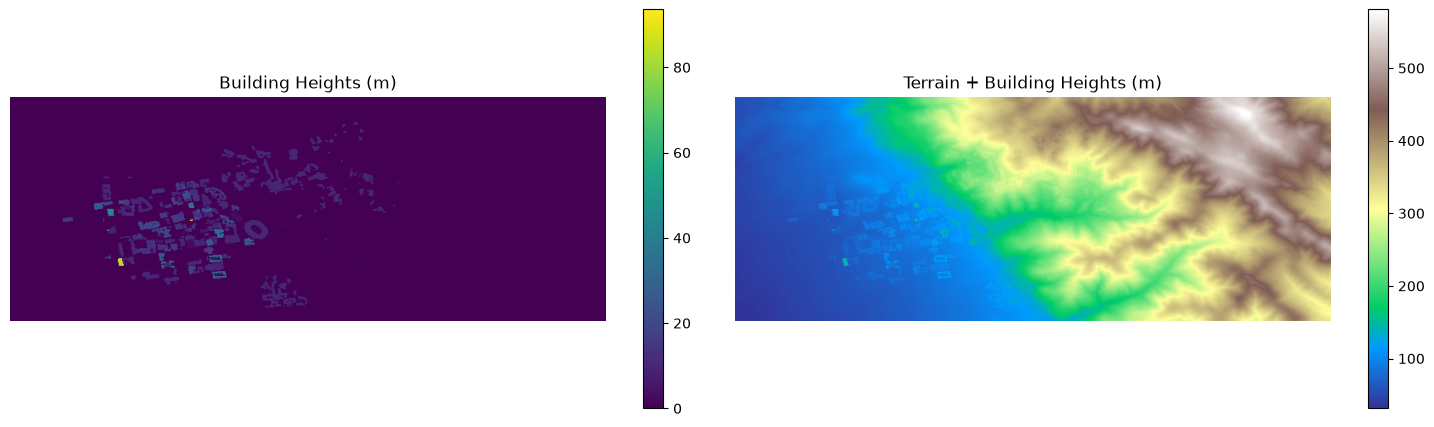

In [94]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

with rasterio.open(height_raster_path) as src:
    heights = src.read(1, masked=True)

with rasterio.open(surface_path) as src:
    surface = src.read(1, masked=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

im1 = axes[0].imshow(heights, cmap="viridis", vmin=0)
axes[0].set_title("Building Heights (m)")
axes[0].axis("off")
plt.colorbar(im1, ax=axes[0], shrink=0.7)

im2 = axes[1].imshow(surface, cmap="terrain")
axes[1].set_title("Terrain + Building Heights (m)")
axes[1].axis("off")
plt.colorbar(im2, ax=axes[1], shrink=0.7)

plt.tight_layout()
plt.show()


In [95]:

import os
import numpy as np
import rasterio
import geopandas as gpd

from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.features import rasterize
from rasterio.transform import rowcol

dem_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/output_USGS10m.tif"
buildings_path = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_campus_buildings_with_heights.gpkg"

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"
projected_dem_path = f"{out_dir}/berkeley_dem_utm10n.tif"
height_path = f"{out_dir}/berkeley_building_heights_utm10n.tif"
surface_path = f"{out_dir}/berkeley_surface_utm10n.tif"

target_crs = "EPSG:26910"

# Reproject DEM into meters
with rasterio.open(dem_path) as src:
    transform, width, height = calculate_default_transform(
        src.crs, target_crs, src.width, src.height, *src.bounds,
        resolution=10
    )
    profile = src.profile.copy()
    profile.update(
        crs=target_crs,
        transform=transform,
        width=width,
        height=height,
        dtype="float32",
        count=1,
        nodata=-9999,
        compress="lzw"
    )

    with rasterio.open(projected_dem_path, "w", **profile) as dst:
        reproject(
            source=rasterio.band(src, 1),
            destination=rasterio.band(dst, 1),
            src_transform=src.transform,
            src_crs=src.crs,
            src_nodata=src.nodata,
            dst_transform=transform,
            dst_crs=target_crs,
            dst_nodata=-9999,
            resampling=Resampling.bilinear
        )

# Load and reproject building footprints
buildings = gpd.read_file(buildings_path, layer="buildings").to_crs(target_crs)
buildings = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
    & buildings["viewshed_height_m"].notna()
].copy()

with rasterio.open(projected_dem_path) as src:
    dem = src.read(1)
    valid = (dem != src.nodata) & np.isfinite(dem)
    profile = src.profile.copy()
    transform = src.transform
    shape = dem.shape

# Rasterize building heights on exactly the DEM grid
height_array = rasterize(
    (
        (geom, float(h))
        for geom, h in zip(
            buildings.geometry,
            buildings["viewshed_height_m"]
        )
    ),
    out_shape=shape,
    transform=transform,
    fill=0,
    dtype="float32",
    all_touched=True
)

height_array[~valid] = -9999

with rasterio.open(height_path, "w", **profile) as dst:
    dst.write(height_array, 1)

# Create terrain + building surface
surface = np.full(shape, -9999, dtype="float32")
surface[valid] = dem[valid]
inside = valid & (height_array > 0)
surface[inside] += height_array[inside]

surface_profile = profile.copy()
surface_profile.update(compress="lzw")

with rasterio.open(surface_path, "w", **surface_profile) as dst:
    dst.write(surface, 1)

print("Projected DEM:", projected_dem_path)
print("Building heights:", height_path)
print("Combined surface:", surface_path)
print("Grid size:", width, "x", height)


Projected DEM: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_dem_utm10n.tif
Building heights: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_building_heights_utm10n.tif
Combined surface: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/berkeley_surface_utm10n.tif
Grid size: 574 x 276


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/3360596474.py:60: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = src.read(1)


In [96]:
from osgeo import gdal
print("GDAL version:", gdal.VersionInfo("--version"))

GDAL version: GDAL 3.11.4 "Eganville", released 2025/09/04


In [97]:

import os
import numpy as np
import rasterio
import geopandas as gpd

from osgeo import gdal
from rasterio.transform import rowcol
from rasterio.features import geometry_mask

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

dem_path = f"{out_dir}/berkeley_dem_utm10n.tif"
surface_path = f"{out_dir}/berkeley_surface_utm10n.tif"

surface_tower_path = f"{out_dir}/berkeley_surface_with_campanile_top.tif"
viewshed_path = f"{out_dir}/campanile_pedestrian_visibility.tif"

# Approximate Campanile location (longitude, latitude)
campanile_lon = -122.2577
campanile_lat = 37.8721

# Campanile height in meters
tower_height_m = 93.6

# Pedestrian eye height above the local surface
pedestrian_eye_height_m = 1.7

# Reproject the Campanile point into the DEM CRS
point = gpd.GeoDataFrame(
    {"name": ["Campanile"]},
    geometry=gpd.points_from_xy(
        [campanile_lon], [campanile_lat]
    ),
    crs="EPSG:4326"
).to_crs("EPSG:26910")

tower_x = point.geometry.iloc[0].x
tower_y = point.geometry.iloc[0].y

# Set the Campanile pixel to its approximate top elevation.
# The top is terrain elevation + tower height.
with rasterio.open(dem_path) as dem_src:
    dem = dem_src.read(1)
    profile = dem_src.profile.copy()
    transform = dem_src.transform
    nodata = dem_src.nodata

    row, col = rowcol(transform, tower_x, tower_y)

    if not (0 <= row < dem_src.height and 0 <= col < dem_src.width):
        raise ValueError(
            "Campanile point is outside the DEM. Check its coordinates."
        )

    ground_elevation = float(dem[row, col])

    if nodata is not None and np.isclose(ground_elevation, nodata):
        raise ValueError("Campanile point falls on a NoData DEM cell.")

with rasterio.open(surface_path) as src:
    surface = src.read(1)
    surface_profile = src.profile.copy()
    surface_nodata = src.nodata

# Use the DEM terrain elevation at the tower's location,
# then set this pixel to the tower's top elevation.
surface[row, col] = ground_elevation + tower_height_m

with rasterio.open(surface_tower_path, "w", **surface_profile) as dst:
    dst.write(surface, 1)

# Run GDAL viewshed.
# Observer is at the tower-top pixel; targets are 1.7 m above the surface.
src_ds = gdal.Open(surface_tower_path, gdal.GA_ReadOnly)

if src_ds is None:
    raise RuntimeError("Could not open the surface raster with GDAL.")

band = src_ds.GetRasterBand(1)
driver = gdal.GetDriverByName("GTiff")

result_ds = gdal.ViewshedGenerate(
    band,
    "GTiff",
    viewshed_path,
    ["COMPRESS=LZW"],
    tower_x,
    tower_y,
    0.0,                         # observer is already at tower-top elevation
    pedestrian_eye_height_m,     # pedestrian eye height
    1,                           # visible
    0,                           # not visible
    0,                           # out of range
    255,                         # output NoData
    0.0,                         # curvature coefficient; ignored here
    gdal.GVOT_NORMAL,
    0.0                          # max distance: entire raster
)

if result_ds is None:
    raise RuntimeError("GDAL did not create a viewshed raster.")

result_ds = None
src_ds = None

# Clip the visibility result to the campus boundary
if "campus" not in globals():
    raise NameError(
        "The campus GeoDataFrame is not in memory. "
        "Reload or recreate your campus boundary first."
    )

campus_projected = campus.to_crs("EPSG:26910")

with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    height, width = src.height, src.width

inside_campus = geometry_mask(
    campus_projected.geometry,
    out_shape=(height, width),
    transform=transform,
    invert=True,
    all_touched=False
)

# Keep visibility values inside campus and mark outside as NoData
visibility[~inside_campus] = 255

profile.update(dtype="uint8", nodata=255, compress="lzw")

with rasterio.open(viewshed_path, "w", **profile) as dst:
    dst.write(visibility.astype("uint8"), 1)

print("Viewshed saved:", viewshed_path)
print("Campanile ground elevation:", round(ground_elevation, 2), "m")
print("Approximate tower-top elevation:",
      round(ground_elevation + tower_height_m, 2), "m")
print("Visible cells inside campus:",
      int(np.sum((visibility == 1) & inside_campus)))


Viewshed saved: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/campanile_pedestrian_visibility.tif
Campanile ground elevation: 98.52 m
Approximate tower-top elevation: 192.12 m
Visible cells inside campus: 22403


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/40496169.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = dem_src.read(1)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/40496169.py:61: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  surface = src.read(1)
/opt/anaconda3/envs/geospatial/lib/python3.14/site-packages/osgeo/gdal.py:9351: RuntimeWarning: Nodata value found in input DEM. Output will be likely incorrect
  return _gdal.ViewshedGenerate(*args, **kwargs)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/40496169.py:116: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view usin

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/1455153921.py:6: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visibility = src.read(1)


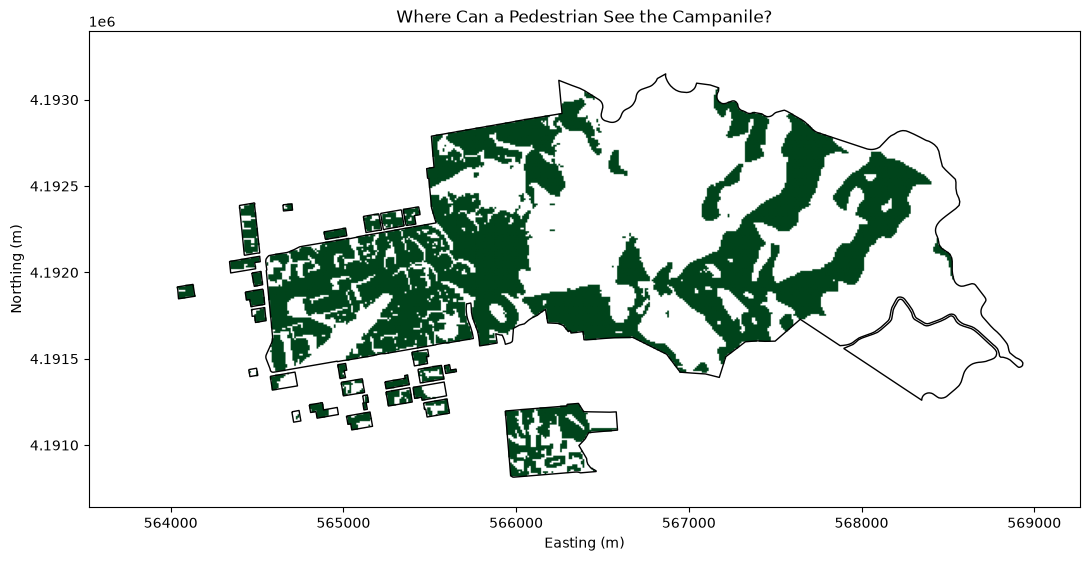

In [98]:

import matplotlib.pyplot as plt
import rasterio
import numpy as np

with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    extent = (
        src.bounds.left, src.bounds.right,
        src.bounds.bottom, src.bounds.top
    )

visible = np.ma.masked_where(
    (visibility != 1) | (visibility == 255),
    visibility
)

fig, ax = plt.subplots(figsize=(11, 11))

ax.imshow(
    visible,
    extent=extent,
    origin="upper",
    cmap="Greens",
    vmin=0,
    vmax=1
)

campus_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

ax.set_title("Where Can a Pedestrian See the Campanile?")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


In [99]:

import numpy as np
import rasterio
import geopandas as gpd
import matplotlib.pyplot as plt

from rasterio.features import rasterize, geometry_mask

out_dir = "/Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs"

viewshed_path = f"{out_dir}/campanile_pedestrian_visibility.tif"
ground_viewshed_path = f"{out_dir}/campanile_visible_pedestrian_ground.tif"

# Reproject building footprints to the viewshed CRS
with rasterio.open(viewshed_path) as src:
    visibility = src.read(1)
    profile = src.profile.copy()
    transform = src.transform
    shape = (src.height, src.width)
    crs = src.crs
    bounds = src.bounds

buildings_projected = buildings.to_crs(crs)

# Burn building footprints into a mask:
# 1 = building footprint, 0 = not a building
building_mask = rasterize(
    (
        (geom, 1)
        for geom in buildings_projected.geometry
        if geom is not None and not geom.is_empty
    ),
    out_shape=shape,
    transform=transform,
    fill=0,
    dtype="uint8",
    all_touched=True
)

# Keep only pixels inside the campus boundary
campus_mask = geometry_mask(
    campus_projected.geometry,
    out_shape=shape,
    transform=transform,
    invert=True,
    all_touched=False
)

# Visible ground cells must be:
# - marked visible by the viewshed
# - inside campus
# - outside building footprints
visible_ground = (
    (visibility == 1)
    & campus_mask
    & (building_mask == 0)
)

# Save: 1 = visible pedestrian ground, 0 = not visible/blocked,
# 255 = outside campus
result = np.zeros(shape, dtype="uint8")
result[visible_ground] = 1
result[~campus_mask] = 255

profile.update(dtype="uint8", count=1, nodata=255, compress="lzw")

with rasterio.open(ground_viewshed_path, "w", **profile) as dst:
    dst.write(result, 1)

print("Saved:", ground_viewshed_path)
print("Visible ground cells:", int(visible_ground.sum()))
print("Building footprint cells removed:", int(building_mask.sum()))


Saved: /Users/sophiameyers/Documents/GitHub/30-day-mapping/outputs/campanile_visible_pedestrian_ground.tif
Visible ground cells: 16127
Building footprint cells removed: 8634


/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/718489887.py:15: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visibility = src.read(1)


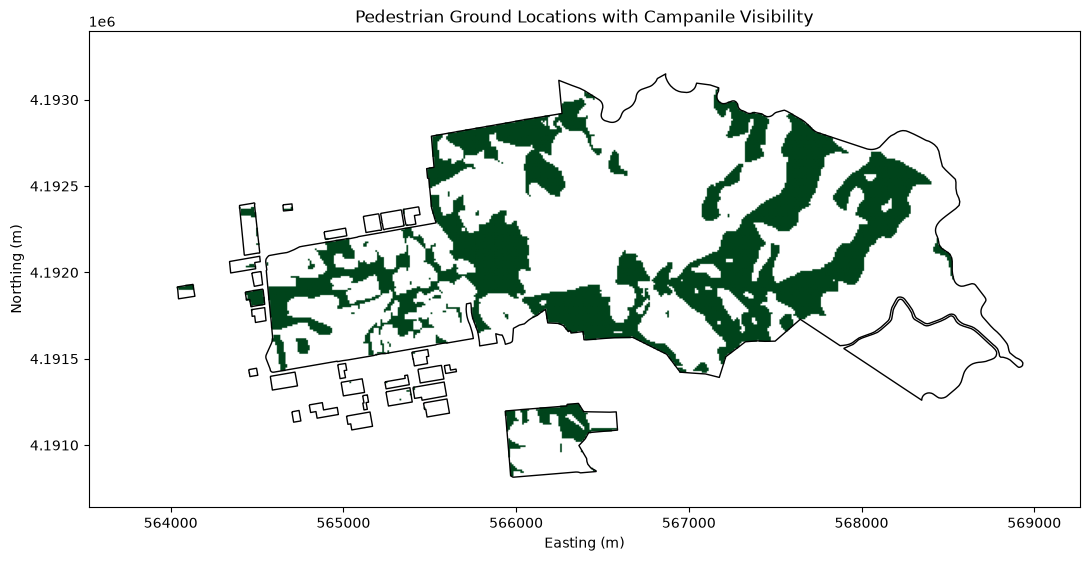

In [100]:

fig, ax = plt.subplots(figsize=(11, 11))

visible = np.ma.masked_where(result != 1, result)

ax.imshow(
    visible,
    extent=(bounds.left, bounds.right, bounds.bottom, bounds.top),
    origin="upper",
    cmap="Greens",
    vmin=0,
    vmax=1
)

campus_projected.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1
)

ax.set_title("Pedestrian Ground Locations with Campanile Visibility")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


# Plotting this

/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/140683887.py:43: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  dem = np.array(src.read(1), dtype=np.float32, copy=True)
/var/folders/3t/qsrrrg8559d3byzjqfp_ybs40000gn/T/ipykernel_26994/140683887.py:72: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  visible_ground = np.array(src.read(1), copy=True)


DEM shape: (276, 574)
X coordinate shape: (276, 574)
Y coordinate shape: (276, 574)
Visible ground cells: 16127
Buildings loaded: 458
DEM CRS: EPSG:26910
DEM dimensions: 574 columns × 276 rows
Finished adding solid building geometry.


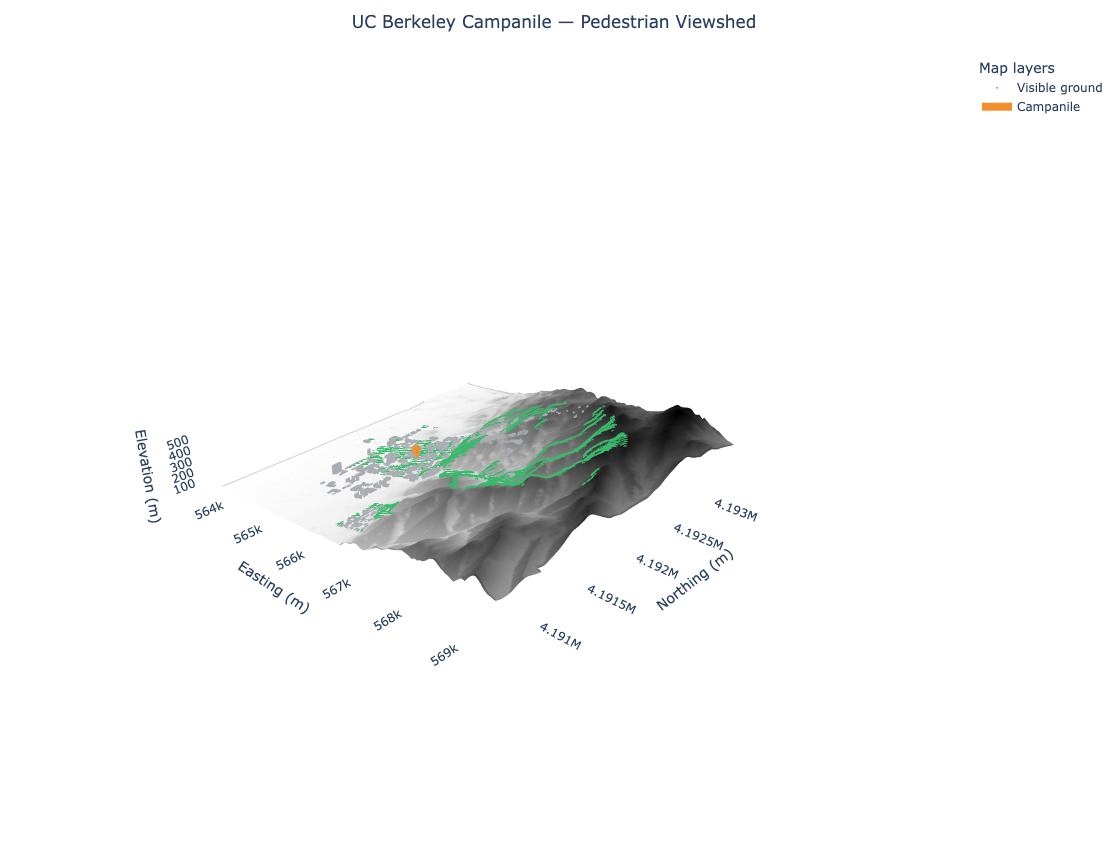

In [101]:
import os
import numpy as np
import geopandas as gpd
import rasterio
import plotly.graph_objects as go

from shapely.geometry import Polygon, MultiPolygon
from rasterio.warp import reproject, Resampling


# ============================================================
# 1. FILE PATHS
# ============================================================

output_dir = (
    "/Users/sophiameyers/Documents/GitHub/"
    "30-day-mapping/outputs"
)

dem_path = os.path.join(output_dir, "berkeley_dem_utm10n.tif")

buildings_path = os.path.join(
    output_dir,
    "berkeley_campus_buildings_with_heights.gpkg"
)

viewshed_path = os.path.join(
    output_dir,
    "campanile_pedestrian_visibility.tif"
)

visible_ground_path = os.path.join(
    output_dir,
    "campanile_visible_pedestrian_ground.tif"
)


# ============================================================
# 2. LOAD TERRAIN AND VIEWSHED RASTERS
# ============================================================

with rasterio.open(dem_path) as src:
    dem = np.array(src.read(1), dtype=np.float32, copy=True)
    dem_transform = src.transform
    dem_crs = src.crs
    dem_bounds = src.bounds
    dem_nodata = src.nodata

# Handle DEM nodata
if dem_nodata is not None:
    dem[dem == dem_nodata] = np.nan

dem[~np.isfinite(dem)] = np.nan

# Create 2D coordinate arrays matching the DEM shape
rows, cols = np.indices(dem.shape)

x_coords = (
    dem_transform.c
    + (cols + 0.5) * dem_transform.a
    + (rows + 0.5) * dem_transform.b
)

y_coords = (
    dem_transform.f
    + (cols + 0.5) * dem_transform.d
    + (rows + 0.5) * dem_transform.e
)

# Load visible-ground raster
with rasterio.open(visible_ground_path) as src:
    visible_ground = np.array(src.read(1), copy=True)
    visible_transform = src.transform
    visible_crs = src.crs
    visible_nodata = src.nodata

# Align the visibility raster to the DEM if necessary
if (
    visible_ground.shape != dem.shape
    or visible_transform != dem_transform
    or visible_crs != dem_crs
):
    visible_ground_aligned = np.zeros(dem.shape, dtype=np.uint8)

    with rasterio.open(visible_ground_path) as src:
        reproject(
            source=rasterio.band(src, 1),
            destination=visible_ground_aligned,
            src_transform=src.transform,
            src_crs=src.crs,
            dst_transform=dem_transform,
            dst_crs=dem_crs,
            resampling=Resampling.nearest,
            src_nodata=src.nodata,
            dst_nodata=0
        )

    visible_ground = visible_ground_aligned

# Identify visible ground cells
visible_mask = (visible_ground == 1) & np.isfinite(dem)

# Extract visible coordinates and elevations
visible_x = x_coords[visible_mask]
visible_y = y_coords[visible_mask]
visible_z = dem[visible_mask]

print("DEM shape:", dem.shape)
print("X coordinate shape:", x_coords.shape)
print("Y coordinate shape:", y_coords.shape)
print("Visible ground cells:", len(visible_x))


# ============================================================
# 3. LOAD BUILDING FOOTPRINTS AND HEIGHTS
# ============================================================

buildings = gpd.read_file(
    buildings_path,
    layer="buildings"
)

# Reproject buildings to match the DEM
if buildings.crs != dem_crs:
    buildings = buildings.to_crs(dem_crs)

# Make sure building heights are numeric
buildings["viewshed_height_m"] = (
    gpd.pd.to_numeric(
        buildings["viewshed_height_m"],
        errors="coerce"
    )
)

# Fill missing heights with the same provisional default
# used in the earlier building-height workflow
buildings["viewshed_height_m"] = (
    buildings["viewshed_height_m"].fillna(10.0)
)

# Remove invalid or empty footprints
buildings = buildings[
    buildings.geometry.notna()
    & ~buildings.geometry.is_empty
].copy()

print(f"Buildings loaded: {len(buildings):,}")
print(f"DEM CRS: {dem_crs}")
print(f"DEM dimensions: {dem.shape[1]} columns × {dem.shape[0]} rows")


# ============================================================
# 4. HELPER: SAMPLE TERRAIN ELEVATION AT A BUILDING
# ============================================================

def get_ground_elevation(geometry, dem_array, transform):
    """
    Estimate the building base elevation from the DEM near
    the footprint centroid. If that pixel is invalid, use
    the median of valid pixels in the surrounding 3x3 window.
    """
    centroid = geometry.centroid

    row, col = rasterio.transform.rowcol(
        transform,
        centroid.x,
        centroid.y
    )

    if (
        0 <= row < dem_array.shape[0]
        and 0 <= col < dem_array.shape[1]
    ):
        value = dem_array[row, col]

        if np.isfinite(value):
            return float(value)

        r0 = max(0, row - 1)
        r1 = min(dem_array.shape[0], row + 2)
        c0 = max(0, col - 1)
        c1 = min(dem_array.shape[1], col + 2)

        window = dem_array[r0:r1, c0:c1]
        valid = window[np.isfinite(window)]

        if valid.size:
            return float(np.median(valid))

    # Last-resort fallback if no DEM value is available
    return 0.0


# ============================================================
# 5. HELPER: ADD A SOLID 3D BUILDING
# ============================================================

def add_solid_building(
    fig,
    polygon,
    base_z,
    height,
    color="#D5D9DF",
    wall_opacity=1.0,
    roof_opacity=1.0
):
    """
    Draw a building as vertical walls plus a flat roof.

    Intended for simple building footprints without interior
    holes. MultiPolygon geometries are handled separately.
    """
    if polygon.is_empty or polygon.geom_type != "Polygon":
        return

    # Use exterior footprint vertices; drop repeated closing vertex
    bx, by = polygon.exterior.xy
    bx = np.asarray(bx[:-1], dtype=float)
    by = np.asarray(by[:-1], dtype=float)

    if len(bx) < 3:
        return

    roof_z = base_z + max(float(height), 1.0)
    n = len(bx)

    # --------------------------------------------------------
    # Solid roof: triangle fan from polygon center
    # --------------------------------------------------------
    center_x = float(np.mean(bx))
    center_y = float(np.mean(by))

    roof_x = list(bx) + [center_x]
    roof_y = list(by) + [center_y]
    roof_z_values = [roof_z] * n + [roof_z]

    center_idx = n

    i = list(range(n))
    j = [(idx + 1) % n for idx in range(n)]
    k = [center_idx] * n

    fig.add_trace(
        go.Mesh3d(
            x=roof_x,
            y=roof_y,
            z=roof_z_values,
            i=i,
            j=j,
            k=k,
            color=color,
            opacity=roof_opacity,
            flatshading=True,
            showscale=False,
            hoverinfo="skip",
            name="Building roofs",
            showlegend=False
        )
    )

    # --------------------------------------------------------
    # Vertical walls: two triangles per footprint edge
    # --------------------------------------------------------
    wall_x = []
    wall_y = []
    wall_z = []
    wall_i = []
    wall_j = []
    wall_k = []

    for idx in range(n):
        nxt = (idx + 1) % n

        # Four corners of this wall
        x1, y1 = bx[idx], by[idx]
        x2, y2 = bx[nxt], by[nxt]

        start = len(wall_x)

        wall_x.extend([x1, x2, x2, x1])
        wall_y.extend([y1, y2, y2, y1])
        wall_z.extend([
            base_z,
            base_z,
            roof_z,
            roof_z
        ])

        # Two triangles form one rectangular wall
        wall_i.extend([start, start])
        wall_j.extend([start + 1, start + 2])
        wall_k.extend([start + 2, start + 3])

    fig.add_trace(
        go.Mesh3d(
            x=wall_x,
            y=wall_y,
            z=wall_z,
            i=wall_i,
            j=wall_j,
            k=wall_k,
            color=color,
            opacity=wall_opacity,
            flatshading=True,
            showscale=False,
            hoverinfo="skip",
            name="Building walls",
            showlegend=False
        )
    )


# ============================================================
# 6. CREATE A FRESH 3D FIGURE
# ============================================================

fig = go.Figure()

# ------------------------------------------------------------
# Terrain surface
# ------------------------------------------------------------

# Downsample terrain for a responsive Plotly scene.
# This changes only the visualization, not your source DEM.
terrain_step = 3

fig.add_trace(
    go.Surface(
        x=x_coords[::terrain_step, ::terrain_step],
        y=y_coords[::terrain_step, ::terrain_step],
        z=dem[::terrain_step, ::terrain_step],
        colorscale="Greys",
        showscale=False,
        opacity=1.0,
        name="Terrain",
        hovertemplate=(
            "Easting: %{x:.1f} m<br>"
            "Northing: %{y:.1f} m<br>"
            "Elevation: %{z:.1f} m"
            "<extra>Terrain</extra>"
        )
    )
)

# ------------------------------------------------------------
# Visible pedestrian ground
# ------------------------------------------------------------

# Plotly can become slow with hundreds of thousands of markers.
# Increase marker_step to 2, 3, etc. if rendering is slow.
marker_step = 3

visible_x_plot = visible_x[::marker_step]
visible_y_plot = visible_y[::marker_step]
visible_z_plot = visible_z[::marker_step]

fig.add_trace(
    go.Scatter3d(
        x=visible_x_plot,
        y=visible_y_plot,
        z=visible_z_plot + 0.35,
        mode="markers",
        marker=dict(
            size=2,
            color="#39B96B",
            opacity=0.85
        ),
        name="Visible ground",
        hoverinfo="skip"
    )
)


# ============================================================
# 7. ADD SOLID 3D BUILDINGS
# ============================================================

# Use a shared DEM dataset for all base-elevation samples
with rasterio.open(dem_path) as dem_src:

    for _, row in buildings.iterrows():

        geometry = row.geometry
        height = row["viewshed_height_m"]

        if geometry is None or geometry.is_empty:
            continue

        if not np.isfinite(height) or height <= 0:
            height = 10.0

        # Estimate ground elevation under the building
        base_z = get_ground_elevation(
            geometry,
            dem,
            dem_transform
        )

        # Handle both individual polygons and multipolygons
        if geometry.geom_type == "Polygon":
            polygons = [geometry]

        elif geometry.geom_type == "MultiPolygon":
            polygons = list(geometry.geoms)

        else:
            continue

        for polygon in polygons:
            add_solid_building(
                fig=fig,
                polygon=polygon,
                base_z=base_z,
                height=height,
                color="#D5D9DF",
                wall_opacity=1.0,
                roof_opacity=1.0
            )

print("Finished adding solid building geometry.")


# ============================================================
# 8. ADD THE CAMPANILE MARKER
# ============================================================

# Campanile location in longitude/latitude
campanile_lon = -122.2577
campanile_lat = 37.8721

# Transform Campanile coordinates into the projected DEM CRS
from pyproj import Transformer

transformer = Transformer.from_crs(
    "EPSG:4326",
    dem_crs,
    always_xy=True
)

campanile_x, campanile_y = transformer.transform(
    campanile_lon,
    campanile_lat
)

campanile_base_z = get_ground_elevation(
    # Small point-like geometry for sampling
    gpd.GeoSeries(
        [gpd.points_from_xy([campanile_x], [campanile_y])[0]],
        crs=dem_crs
    ).iloc[0],
    dem,
    dem_transform
)

campanile_height = 93.6
campanile_top_z = campanile_base_z + campanile_height

# Campanile vertical marker
fig.add_trace(
    go.Scatter3d(
        x=[campanile_x, campanile_x],
        y=[campanile_y, campanile_y],
        z=[campanile_base_z, campanile_top_z],
        mode="lines",
        line=dict(
            color="#F28E2B",
            width=8
        ),
        name="Campanile",
        hovertemplate=(
            "Sather Tower (Campanile)<br>"
            "Height: 93.6 m"
            "<extra></extra>"
        )
    )
)

# Campanile top point
fig.add_trace(
    go.Scatter3d(
        x=[campanile_x],
        y=[campanile_y],
        z=[campanile_top_z],
        mode="markers",
        marker=dict(
            size=5,
            color="#F28E2B"
        ),
        showlegend=False,
        hoverinfo="skip"
    )
)


# ============================================================
# 9. FORMAT THE 3D SCENE
# ============================================================

# Use equal scaling for horizontal axes and a more exaggerated
# vertical scale so terrain and buildings are easier to see.
fig.update_layout(
    title=dict(
        text="UC Berkeley Campanile — Pedestrian Viewshed",
        x=0.5
    ),
    scene=dict(
        xaxis=dict(
            title="Easting (m)",
            showbackground=False,
            showgrid=False
        ),
        yaxis=dict(
            title="Northing (m)",
            showbackground=False,
            showgrid=False
        ),
        zaxis=dict(
            title="Elevation (m)",
            showbackground=False,
            showgrid=True
        ),
        aspectmode="manual",
        aspectratio=dict(
            x=1,
            y=1,
            z=0.18
        ),
        camera=dict(
            eye=dict(
                x=1.5,
                y=-1.6,
                z=1.1
            )
        )
    ),
    legend=dict(
        title="Map layers"
    ),
    margin=dict(
        l=0,
        r=0,
        t=55,
        b=0
    ),
    height=850
)

fig.show()

# now need to style it (fix the stadium and the bilding heights